# 04 · Direct Preference Optimization: RLHF Without the RL

## Overview

| # | Notebook | Idea | What it fixes | What it leaves open |
|---|---|---|---|---|
| 01 | Pretraining | Next-token prediction on raw text | Knowledge: the model *can* add | Doesn't follow instructions |
| 02 | SFT + LoRA | Imitate demonstrations | Follows the chat format | Copies demonstrators' mistakes; forgets |
| 03 | Reward model + PPO | Learn a reward from preferences, optimise it | Can go beyond imitation | Reward hacking; four models; fragile |
| **04** | **DPO family** | **Optimise preferences directly, no RL loop** | **Simple and stable** | **Offline: only re-weights existing behaviour** |
| 05 | GRPO / RLVR | Online RL against a verifier | Verifiable gains, no value network | Sharpens, rarely expands; needs a capable start |
| 06 | Diffusion | Learn to denoise | Stable, high-quality generation | Matches data, not *goals*; slow sampling |
| 07 | Diffusion post-training | Fine-tune and reward-align a denoiser | Steer generation to a goal | Reward hacking again; still slow |
| 08 | Distillation | Few-step students | 10-100x faster sampling | Small denoisers don't scale |
| 09 | Diffusion transformers | Tokens + adaLN + flow matching | Scalable, flexible conditioning | Needs post-training too |
| 10 | Capstone | GRPO and DPO on a DiT; diffusion LMs | Unifies both threads | → the research frontier |

PPO in notebook 03 needed four networks, an online sampling loop and a stack of hyperparameters, and it
still overoptimised its reward model. **Direct Preference Optimization (DPO)** ([Rafailov et al., 2023](https://arxiv.org/abs/2305.18290))
starts from the same KL-regularised objective and shows that its optimum can be written in closed form.
Preference learning then becomes a *supervised* loss on the preference pairs, with no reward model, no
value function and no sampling during training. DPO and its variants became the default for open
models within a year, and several later variants followed:

* **IPO** ([Azar et al., 2023](https://arxiv.org/abs/2310.12036)) fixes DPO's tendency to overfit deterministic preferences;
* **KTO** ([Ethayarajh et al., 2024](https://arxiv.org/abs/2402.01306)) learns from unpaired thumbs-up / thumbs-down signals;
* **SimPO** ([Meng et al., 2024](https://arxiv.org/abs/2405.14734)) removes the reference model and normalises by length;
* **ORPO** ([Hong et al., 2024](https://arxiv.org/abs/2403.07691)) goes further and folds the preference term into the SFT loss itself (discussed, not trained here).

We train all four on **exactly the same ~8,300 preference pairs** as notebook 03 and compare them with PPO
on the shared scorecard.

## Learning objectives

1. Derive the DPO loss from the KL-regularised RLHF objective, and explain why the partition function cancels.
2. Implement DPO, IPO, KTO and SimPO as a few lines each on top of `sequence_logprobs`.
3. Observe **likelihood displacement**: DPO can lower the probability of the *chosen* answers ([Razin et al., 2024](https://arxiv.org/abs/2410.08847), [Pal et al., 2024](https://arxiv.org/abs/2402.13228)).
4. Measure the limitation of offline training, and how a round of fresh, on-policy preference data changes it ([Tajwar et al., 2024](https://arxiv.org/abs/2404.14367), [Xu et al., 2024](https://arxiv.org/abs/2404.10719)).

**Runtime:** about 6 minutes on a laptop CPU.

In [1]:
import sys, time, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
sys.path.insert(0, ".")
from ptlib import tasks, lm, align, metrics, set_seed
torch.set_num_threads(min(8, torch.get_num_threads()))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
sft = align.get_sft()
prefs = align.get_preferences(n_prompts=24000, seed=0)       # notebook 03's dataset (cached)
heldout, train = prefs[-600:], prefs[:-600]
print(f"{len(train)} training pairs, {len(heldout)} held-out pairs")

8336 training pairs, 600 held-out pairs


## 1. Deriving DPO

Start from the objective PPO optimised in notebook 03, for a fixed reward $r$:
$$\max_\pi\; \mathbb{E}_{y \sim \pi(\cdot\mid x)}\big[r(x,y)\big] - \beta\,\mathrm{KL}\big(\pi(\cdot\mid x)\,\|\,\pi_\text{ref}(\cdot\mid x)\big).$$

**Step 1, the optimum in closed form.** This is maximised by a re-weighting of the reference policy:
$$\pi^*(y\mid x) = \frac{1}{Z(x)}\,\pi_\text{ref}(y\mid x)\,\exp\!\big(r(x,y)/\beta\big), \qquad Z(x) = \sum_y \pi_\text{ref}(y\mid x)\,e^{r(x,y)/\beta}.$$
$Z(x)$ sums over every possible answer, so it is intractable. That is why RLHF uses sampling-based RL instead.

**Step 2, invert it.** Solve for the reward in terms of the optimal policy:
$$r(x,y) = \beta \log\frac{\pi^*(y\mid x)}{\pi_\text{ref}(y\mid x)} + \beta \log Z(x).$$

**Step 3, substitute into Bradley–Terry.** Only reward *differences* enter $P(y_w \succ y_l)$, so $\beta\log Z(x)$
cancels. Parameterise $\pi^*$ by the policy $\pi_\theta$ and maximise the likelihood of the preferences:
$$\mathcal{L}_\text{DPO}(\theta) = -\,\mathbb{E}\Big[\log\sigma\Big(\beta\log\frac{\pi_\theta(y_w\mid x)}{\pi_\text{ref}(y_w\mid x)} - \beta\log\frac{\pi_\theta(y_l\mid x)}{\pi_\text{ref}(y_l\mid x)}\Big)\Big].$$

"Your language model is secretly a reward model": $\hat r_\theta(x,y) = \beta\log\pi_\theta(y\mid x)/\pi_\text{ref}(y\mid x)$
is an **implicit reward**, and DPO fits it with the same loss the reward model used in notebook 03. The gradient
weights each pair by $\sigma(\hat r_\theta(y_l) - \hat r_\theta(y_w))$, i.e. by how wrong the implicit reward currently is.

## 2. The losses in code

Every method needs only the summed log-probabilities of the chosen and rejected answers under the policy
and the (frozen) reference; the reference log-probs are computed once, before training.

In [2]:
print(inspect.getsource(align.preference_loss))
print(inspect.getsource(align.kto_loss))

def preference_loss(kind, pc, pr, rc, rr, beta=0.1, len_c=None, len_r=None, gamma=0.5):
    """pc/pr: policy log-probs of chosen/rejected; rc/rr: reference log-probs (summed over tokens).

    dpo   : -log sigmoid(beta * [(pc - rc) - (pr - rr)])                      Rafailov et al., 2023
    ipo   : ([(pc - rc) - (pr - rr)] - 1 / (2 beta))^2                         Azar et al., 2023
    simpo : -log sigmoid(beta * [pc/|c| - pr/|r|] - gamma), no reference       Meng et al., 2024
    """
    h = (pc - rc) - (pr - rr)
    if kind == "dpo":
        return -F.logsigmoid(beta * h).mean()
    if kind == "ipo":
        return ((h - 1 / (2 * beta)) ** 2).mean()
    if kind == "simpo":
        return -F.logsigmoid(beta * (pc / len_c - pr / len_r) - gamma).mean()
    raise ValueError(kind)

def kto_loss(p, r, desirable, beta=0.1, z_ref=0.0, lam_d=1.0, lam_u=1.0):
    """KTO (Ethayarajh et al., 2024): unpaired thumbs-up / thumbs-down examples.

    Reward r_theta = log pi/pi_ref; value = sigmoid(b

The variants change one design choice each:

| Method | Loss on $h = \hat r(y_w) - \hat r(y_l)$ (up to $\beta$) | Why |
|---|---|---|
| DPO | $-\log\sigma(\beta h)$ | Bradley–Terry likelihood |
| IPO | $(h - \tfrac{1}{2\beta})^2$ | Bounded target: DPO's loss keeps pushing $h \to \infty$ when preferences are near-deterministic |
| KTO | $1 - \sigma(\beta(\hat r(y) - z_\text{ref}))$ for good $y$, $1 - \sigma(\beta(z_\text{ref} - \hat r(y)))$ for bad $y$ | Needs only per-answer labels, not pairs (here: chosen = good, rejected = bad) |
| SimPO | $-\log\sigma\big(\beta(\tfrac{\log\pi(y_w)}{|y_w|} - \tfrac{\log\pi(y_l)}{|y_l|}) - \gamma\big)$ | No reference model; length-normalised; margin $\gamma$ |

## 3. Training all four

In [3]:
configs = {"DPO": ("dpo", 0.1), "IPO": ("ipo", 0.1), "KTO": ("kto", 0.1), "SimPO": ("simpo", 2.0)}
res, curves, models = {}, {}, {}
ref = align.get_sft(verbose=False).requires_grad_(False)
for name, (kind, beta) in configs.items():
    policy = align.get_sft(verbose=False)
    t0 = time.time()
    curves[name] = align.offline_preference_training(policy, ref, train, kind=kind, beta=beta, epochs=2, lr=5e-6,
                                                     track=heldout[:200], log=False)
    secs = time.time() - t0
    res[name] = {**align.evaluate(policy), "kl_to_sft": align.kl_to_ref(policy, ref), "seconds": secs}
    models[name] = policy
    print(f"{name:6s} done in {secs:.0f}s:", {k: round(v, 3) for k, v in res[name].items()})

DPO    done in 36s: {'greedy_acc': 0.965, 'sampled_acc': 0.838, 'well_formed': 0.938, 'sentence_style': 0.938, 'mean_len': 19.73, 'kl_to_sft': 1.247, 'seconds': 36.464}
IPO    done in 36s: {'greedy_acc': 1.0, 'sampled_acc': 0.905, 'well_formed': 0.985, 'sentence_style': 0.792, 'mean_len': 16.698, 'kl_to_sft': 0.264, 'seconds': 36.379}
KTO    done in 43s: {'greedy_acc': 0.955, 'sampled_acc': 0.79, 'well_formed': 0.91, 'sentence_style': 0.91, 'mean_len': 19.83, 'kl_to_sft': 1.672, 'seconds': 42.569}
SimPO  done in 37s: {'greedy_acc': 0.993, 'sampled_acc': 0.855, 'well_formed': 0.99, 'sentence_style': 0.323, 'mean_len': 9.435, 'kl_to_sft': 0.356, 'seconds': 37.049}


,greedy_acc,sampled_acc,well_formed,sentence_style,mean_len,kl_to_sft,seconds
SFT (reference),0.998,0.775,0.995,0.598,13.545,0.000,NaN
"PPO vs RM-small, beta=0.05",1.000,0.895,0.998,0.998,19.588,0.582,NaN
"PPO vs RM-large, beta=0.05",0.732,0.635,1.000,1.000,19.705,1.917,NaN
"PPO vs RM-large, beta=0",0.005,0.005,0.988,0.988,19.990,20.293,NaN
"PPO vs verifier, beta=0.05",1.000,0.948,0.985,0.758,16.152,0.270,NaN
DPO,0.965,0.838,0.938,0.938,19.730,1.247,36.464
IPO,1.000,0.905,0.985,0.792,16.698,0.264,36.379
KTO,0.955,0.790,0.910,0.910,19.830,1.672,42.569
SimPO,0.992,0.855,0.990,0.322,9.435,0.356,37.049


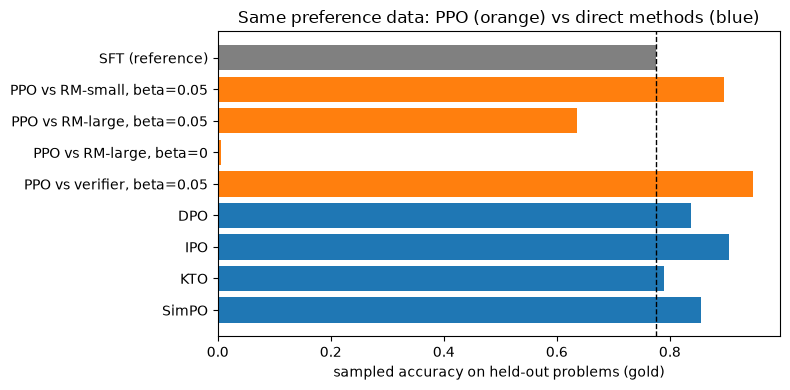

In [4]:
sc = metrics.load_scorecard()
ppo = sc[(sc.notebook == "03_rlhf_ppo") & (sc.family == "lm")].set_index("model")
compare = pd.concat([pd.DataFrame({"SFT (reference)": {**align.evaluate(sft), "kl_to_sft": 0.0}}).T,
                     ppo[["greedy_acc", "sampled_acc", "well_formed", "sentence_style", "mean_len", "kl_to_sft"]],
                     pd.DataFrame(res).T])
display(compare[["greedy_acc", "sampled_acc", "well_formed", "sentence_style", "mean_len", "kl_to_sft", "seconds"]].round(3))

fig, ax = plt.subplots(figsize=(8, 4))
c = ["0.5"] + ["tab:orange"] * len(ppo) + ["tab:blue"] * len(res)
ax.barh(compare.index[::-1], compare.sampled_acc[::-1], color=c[::-1])
ax.axvline(compare.loc["SFT (reference)", "sampled_acc"], ls="--", c="k", lw=1)
ax.set_xlabel("sampled accuracy on held-out problems (gold)"); ax.set_title("Same preference data: PPO (orange) vs direct methods (blue)")
fig.tight_layout(); plt.show()

**What the comparison shows.** Read the table row by row; three things matter.

* The direct methods improve on SFT using the same data, in a few tens of seconds, with no reward model, no value network and no sampling. That is why DPO took over open-model post-training.
* IPO, whose bounded target stops the margin from growing without limit, is the strongest direct method here. It matches PPO against the style-only reward model and clearly beats both PPO runs against RM-large, at a fraction of the cost. Only PPO against the verifier is better.
* They also inherit the data's biases. Look at the `sentence_style` column: the preference pairs reward full sentences, and DPO, IPO and KTO all push toward them. SimPO goes the other way. Its length normalisation turns "shorter answer" into a cheap way to raise the average per-token log-probability, so the same data produces a different stylistic drift.
* `well_formed` drops for some methods. Nothing in an offline loss checks what the policy itself generates. The next section shows the mechanism.

## 4. Likelihood displacement

DPO's loss depends only on the **margin** between chosen and rejected log-probabilities. It can be decreased by
pushing the rejected answers down faster than the chosen ones, even if *both* go down. The probability mass
removed from both then lands somewhere: on answers that are in neither set ([Razin et al., 2024](https://arxiv.org/abs/2410.08847)).

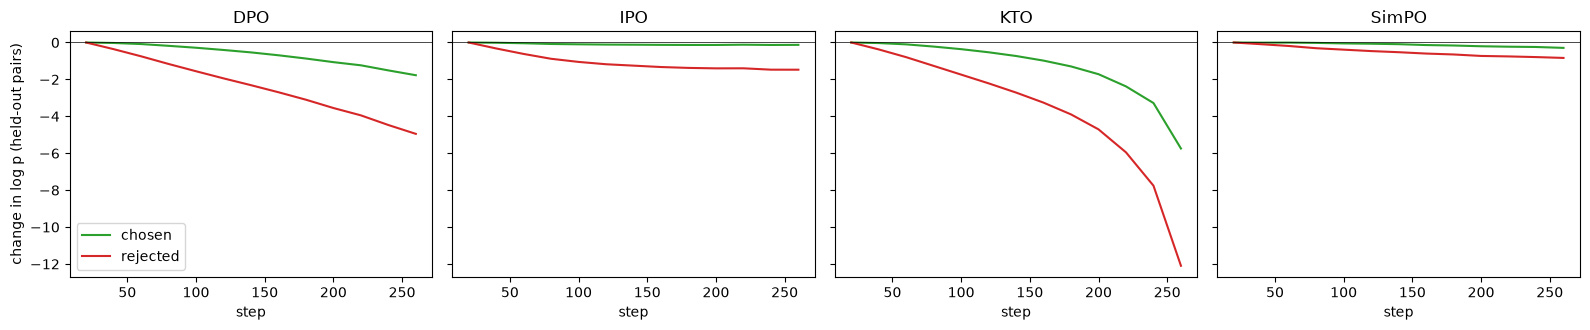

,Δ log p(chosen),Δ log p(rejected)
DPO,-1.77,-4.95
IPO,-0.13,-1.47
KTO,-5.74,-12.10
SimPO,-0.29,-0.84


In [5]:
fig, axes = plt.subplots(1, len(curves), figsize=(16, 3.4), sharey=True)
for ax, (name, h) in zip(axes, curves.items()):
    ax.plot(h.step, h.logp_chosen - h.logp_chosen.iloc[0], label="chosen", c="tab:green")
    ax.plot(h.step, h.logp_rejected - h.logp_rejected.iloc[0], label="rejected", c="tab:red")
    ax.axhline(0, c="k", lw=0.5); ax.set_title(name); ax.set_xlabel("step")
axes[0].set_ylabel("change in log p (held-out pairs)"); axes[0].legend()
fig.tight_layout(); plt.show()
disp = pd.DataFrame({n: {"Δ log p(chosen)": h.logp_chosen.iloc[-1] - h.logp_chosen.iloc[0],
                         "Δ log p(rejected)": h.logp_rejected.iloc[-1] - h.logp_rejected.iloc[0]} for n, h in curves.items()}).T
display(disp.round(2))

Where it happens, the chosen answers lose probability too, sometimes several nats, while the rejected answers lose
more. The loss is happy; the policy has moved mass onto answers that appear in **neither** set. At our
scale those include malformed answers, which matches the drop in `well_formed` above. IPO's bounded target
limits how far the margin is pushed, so it displaces least. DPO-Positive ([Pal et al., 2024](https://arxiv.org/abs/2402.13228)) adds an explicit
penalty when $\log\pi_\theta(y_w)$ falls below $\log\pi_\text{ref}(y_w)$ (Challenge Problem 2).

## 5. The offline limitation, and one round of fresh data

All four methods learn from answers the **SFT model** wrote. They can re-weight that behaviour, but they never
see what the *trained* policy does, including its new mistakes. [Xu et al., 2024](https://arxiv.org/abs/2404.10719) found that well-tuned PPO beats
DPO for exactly this reason, and [Tajwar et al., 2024](https://arxiv.org/abs/2404.14367) argue that preference fine-tuning should use on-policy samples.

The fix is to collect a second round of preferences on samples from the **DPO model** and train again
("iterative" or "online" DPO, as used for Llama 2 and 3: [Touvron et al., 2023](https://arxiv.org/abs/2307.09288), [Grattafiori et al., 2024](https://arxiv.org/abs/2407.21783)).

In [6]:
t0 = time.time()
dpo1 = models["DPO"]
round2 = align.make_preference_pairs(dpo1, n_prompts=12000, seed=5)
print(f"round 2: {len(round2)} new pairs sampled from the DPO policy ({time.time() - t0:.0f}s)")
ref1 = lm.load("sft_lm"); ref1.load_state_dict(dpo1.state_dict()); ref1.requires_grad_(False)   # the new reference
dpo2 = lm.load("sft_lm"); dpo2.load_state_dict(dpo1.state_dict())
align.offline_preference_training(dpo2, ref1, round2, kind="dpo", beta=0.1, epochs=2, lr=5e-6, log=False)
res["DPO, 2nd on-policy round"] = {**align.evaluate(dpo2), "kl_to_sft": align.kl_to_ref(dpo2, ref), "seconds": time.time() - t0}
display(pd.DataFrame(res).T.loc[["DPO", "DPO, 2nd on-policy round"], ["greedy_acc", "sampled_acc", "well_formed", "kl_to_sft"]].round(3))

round 2: 3105 new pairs sampled from the DPO policy (19s)


,greedy_acc,sampled_acc,well_formed,kl_to_sft
DPO,0.965,0.838,0.938,1.247
"DPO, 2nd on-policy round",0.962,0.802,0.968,0.910


The second round did something specific, and the table shows it. It repaired the malformed answers DPO had
introduced (`well_formed` goes back up), because those now appear in the data as rejected answers. It did **not**
raise sampled accuracy, which went slightly down. One round of ~3,000 noisy pairs is not enough to reproduce the
gains reported for iterative DPO at scale. On-policy data fixes the failure modes the policy actually exhibits,
which offline data never contains. Look at what that step needed, though: a labeller available **during training**,
labelling the model's own samples. Our labeller is a
noisy verifier. Once a verifier is available online, the natural move is to optimise it directly, without
pairs at all. That is **reinforcement learning with verifiable rewards**, the subject of notebook 05.

## 6. Scorecard

In [7]:
rows = [dict(model=k, family="lm", **{c: v[c] for c in ["greedy_acc", "sampled_acc", "well_formed", "sentence_style", "mean_len", "kl_to_sft"]})
        for k, v in res.items()]
metrics.append_rows(rows, "04_dpo")
display(metrics.load_scorecard().query("family == 'lm'")[["notebook", "model", "greedy_acc", "sampled_acc", "well_formed", "kl_to_sft"]].round(3))

,notebook,model,greedy_acc,sampled_acc,well_formed,kl_to_sft
0,01_pretraining,base (pretrained),0.000,0.000,0.000,NaN
1,03_rlhf_ppo,"PPO vs RM-small, beta=0.05",1.000,0.895,0.998,0.582
2,03_rlhf_ppo,"PPO vs RM-large, beta=0.05",0.732,0.635,1.000,1.917
3,03_rlhf_ppo,"PPO vs RM-large, beta=0",0.005,0.005,0.988,20.293
4,03_rlhf_ppo,"PPO vs verifier, beta=0.05",1.000,0.948,0.985,0.270
7,02_sft,SFT (full),0.998,0.775,0.995,NaN
8,02_sft,SFT (LoRA r=1),0.828,0.472,0.942,NaN
9,02_sft,SFT (LoRA r=4),0.998,0.758,0.982,NaN
10,02_sft,SFT (LoRA r=16),1.000,0.785,0.995,NaN
11,02_sft,SFT (300 clean demos),0.955,0.672,0.975,NaN


## Challenge Problem 1: The role of β

In DPO, $\beta$ is the strength of the KL regulariser in the objective DPO solves exactly. Train DPO for one
epoch with $\beta \in \{0.03, 0.1, 0.3, 1.0\}$ and plot sampled accuracy and KL to the SFT model against $\beta$.
Which way does a small $\beta$ push the policy, and how does that compare with PPO's $\beta$ in notebook 03?

In [8]:
# Start your code here

### Challenge Problem 1 Solution

,beta,greedy_acc,sampled_acc,well_formed,sentence_style,mean_len,kl_to_sft
0,0.03,0.985,0.870,0.975,0.930,18.922,0.610
1,0.10,0.992,0.880,0.975,0.912,18.640,0.533
2,0.30,0.998,0.905,0.990,0.862,17.662,0.318
3,1.00,1.000,0.880,0.990,0.705,15.252,0.096


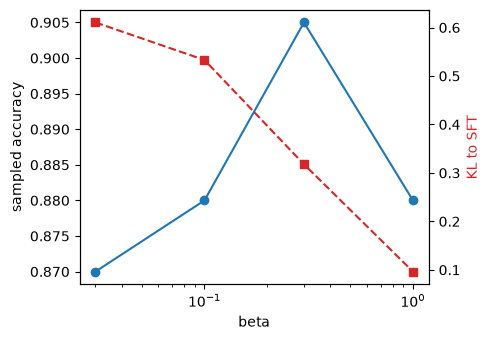

In [9]:
sweep = []
for beta in [0.03, 0.1, 0.3, 1.0]:
    p = align.get_sft(verbose=False)
    align.offline_preference_training(p, ref, train, kind="dpo", beta=beta, epochs=1, lr=5e-6, log=False)
    sweep.append(dict(beta=beta, **align.evaluate(p), kl_to_sft=align.kl_to_ref(p, ref)))
sweep = pd.DataFrame(sweep); display(sweep.round(3))
fig, ax = plt.subplots(figsize=(5, 3.5)); ax.semilogx(sweep.beta, sweep.sampled_acc, "o-", label="sampled acc")
ax2 = ax.twinx(); ax2.semilogx(sweep.beta, sweep.kl_to_sft, "s--", c="tab:red", label="KL"); ax.set_xlabel("beta")
ax.set_ylabel("sampled accuracy"); ax2.set_ylabel("KL to SFT", color="tab:red"); fig.tight_layout(); plt.show()
# Smaller beta = weaker KL constraint. The loss only saturates once the log-ratio margin reaches roughly 1/beta,
# so with small beta the policy must move further from the reference to satisfy the same data. That is the
# role PPO's KL coefficient played in notebook 03, applied through the loss instead of a reward penalty.

## Challenge Problem 2: Fix likelihood displacement with DPO-Positive

[Pal et al., 2024](https://arxiv.org/abs/2402.13228) add a penalty to DPO whenever the policy assigns *less* probability to the chosen answer than the reference does:
$$\mathcal{L}_\text{DPOP} = -\log\sigma\Big(\beta\big[h - \lambda\max(0,\; \log\pi_\text{ref}(y_w) - \log\pi_\theta(y_w))\big]\Big).$$
Implement it in a short training loop (one epoch, $\beta = 0.1$, $\lambda = 5$), and compare the change in
$\log p(\text{chosen})$ on the held-out pairs and the well-formedness with plain DPO.

In [10]:
# Start your code here

### Challenge Problem 2 Solution

In [11]:
import torch.nn.functional as F
set_seed(0)
p = align.get_sft(verbose=False)
opt = torch.optim.AdamW(p.parameters(), lr=5e-6)
P = [d["prompt"] for d in train]
with torch.no_grad():
    RC = torch.cat([lm.sequence_logprobs(ref, P[i:i+512], [d["chosen"] for d in train[i:i+512]]) for i in range(0, len(train), 512)])
    RR = torch.cat([lm.sequence_logprobs(ref, P[i:i+512], [d["rejected"] for d in train[i:i+512]]) for i in range(0, len(train), 512)])
hp = [d["prompt"] for d in heldout[:200]]; hc = [d["chosen"] for d in heldout[:200]]
with torch.no_grad(): before = lm.sequence_logprobs(p, hp, hc).mean().item()
perm = np.random.permutation(len(train)); p.train()
for i in range(0, len(train), 64):
    idx = perm[i:i + 64]; b = [train[j] for j in idx]; pr = [d["prompt"] for d in b]
    pc, pj = lm.sequence_logprobs(p, pr, [d["chosen"] for d in b]), lm.sequence_logprobs(p, pr, [d["rejected"] for d in b])
    h = (pc - RC[idx]) - (pj - RR[idx])
    loss = -F.logsigmoid(0.1 * (h - 5.0 * (RC[idx] - pc).clamp(min=0))).mean()
    opt.zero_grad(); loss.backward(); opt.step()
p.eval()
with torch.no_grad(): after = lm.sequence_logprobs(p, hp, hc).mean().item()
print(f"DPOP: change in log p(chosen) {after - before:+.2f} nats (DPO, 2 epochs: {disp.loc['DPO', 'Δ log p(chosen)']:+.2f})")
print("DPOP:", {k: round(v, 3) for k, v in align.evaluate(p).items()})

DPOP: change in log p(chosen) +0.05 nats (DPO, 2 epochs: -1.77)
DPOP: {'greedy_acc': 1.0, 'sampled_acc': 0.855, 'well_formed': 0.99, 'sentence_style': 0.627, 'mean_len': 14.088}


## Final summary

* The KL-regularised RLHF objective has a closed-form optimum. Inverting it turns the policy into an **implicit reward model**, and preference learning becomes a supervised loss (DPO).
* DPO, IPO, KTO and SimPO each change one design choice (likelihood vs bounded target, paired vs unpaired, with or without a reference). On the same data they reach comparable accuracy with very different side effects, in style and in well-formedness.
* **Likelihood displacement:** a margin-based loss can lower the probability of the preferred answers and move mass onto answers that are in neither set.
* Offline methods only re-weight the behaviour present in their data. Fresh, on-policy preferences help, and once a verifier can label samples online, it is simpler to optimise it directly: notebook 05.

## References

* Rafael Rafailov, Archit Sharma, Eric Mitchell et al. (2023). **Direct Preference Optimization: Your Language Model is Secretly a Reward Model**. arXiv:2305.18290. [arxiv.org/abs/2305.18290](https://arxiv.org/abs/2305.18290)
* Mohammad Gheshlaghi Azar, Mark Rowland, Bilal Piot et al. (2023). **A General Theoretical Paradigm to Understand Learning from Human Preferences**. arXiv:2310.12036. [arxiv.org/abs/2310.12036](https://arxiv.org/abs/2310.12036)
* Kawin Ethayarajh, Winnie Xu, Niklas Muennighoff et al. (2024). **KTO: Model Alignment as Prospect Theoretic Optimization**. arXiv:2402.01306. [arxiv.org/abs/2402.01306](https://arxiv.org/abs/2402.01306)
* Yu Meng, Mengzhou Xia, Danqi Chen (2024). **SimPO: Simple Preference Optimization with a Reference-Free Reward**. arXiv:2405.14734. [arxiv.org/abs/2405.14734](https://arxiv.org/abs/2405.14734)
* Jiwoo Hong, Noah Lee, James Thorne (2024). **ORPO: Monolithic Preference Optimization without Reference Model**. arXiv:2403.07691. [arxiv.org/abs/2403.07691](https://arxiv.org/abs/2403.07691)
* Arka Pal, Deep Karkhanis, Samuel Dooley et al. (2024). **Smaug: Fixing Failure Modes of Preference Optimisation with DPO-Positive**. arXiv:2402.13228. [arxiv.org/abs/2402.13228](https://arxiv.org/abs/2402.13228)
* Noam Razin, Sadhika Malladi, Adithya Bhaskar et al. (2024). **Unintentional Unalignment: Likelihood Displacement in Direct Preference Optimization**. arXiv:2410.08847. [arxiv.org/abs/2410.08847](https://arxiv.org/abs/2410.08847)
* Shusheng Xu, Wei Fu, Jiaxuan Gao et al. (2024). **Is DPO Superior to PPO for LLM Alignment? A Comprehensive Study**. arXiv:2404.10719. [arxiv.org/abs/2404.10719](https://arxiv.org/abs/2404.10719)
* Fahim Tajwar, Anikait Singh, Archit Sharma et al. (2024). **Preference Fine-Tuning of LLMs Should Leverage Suboptimal, On-Policy Data**. arXiv:2404.14367. [arxiv.org/abs/2404.14367](https://arxiv.org/abs/2404.14367)
* Hugo Touvron, Louis Martin, Kevin Stone et al. (2023). **Llama 2: Open Foundation and Fine-Tuned Chat Models**. arXiv:2307.09288. [arxiv.org/abs/2307.09288](https://arxiv.org/abs/2307.09288)
* Aaron Grattafiori, Abhimanyu Dubey, Abhinav Jauhri et al. (2024). **The Llama 3 Herd of Models**. arXiv:2407.21783. [arxiv.org/abs/2407.21783](https://arxiv.org/abs/2407.21783)

The full, verified list for the series is in [`research_papers/README.md`](research_papers/README.md).